# Notebook 02 - Repeatability and Reproducibility

**Milestone:** HV-005  
**Technical Gate:** RR-001  
**Primary Engineering Question:** Repeatability and Reproducibility Variance Structure

This notebook evaluates short-term within-test repeatability, matched run-to-run
variation, and matched day-to-day variation using only qualified
`STATIC / CHARACTERIZATION` evidence from the frozen
`VSM-LAB-DATA-v1.1` release.

The analysis is design-aware. The campaign is not assumed to be a classical
fully crossed Part × Operator × Repeat Gage R&R study.


## 1. Engineering Question

How much of the observed static measurement variation is associated with:

1. short-term within-test repeatability;
2. run-to-run differences under matched operating conditions; and
3. day-to-day differences where the experimental design provides genuinely
   matched day coverage?

The analysis must distinguish measurement-system variation from variation
caused by RH, temperature, direction, and experimental design composition.


## 2. Why This Matters

Static characterization established that the DUT has a persistent negative
pre-calibration error together with condition-dependent structure.

However, characterization alone does not identify how much variation is
associated with repeated readings, repeated runs, or repeated test days.

R&R analysis is therefore needed before calibration and uncertainty modeling
so that observed variation is not incorrectly attributed to one source.


## 3. Scope and Analysis Boundary

### Included

- `STATIC / CHARACTERIZATION` observations only;
- repeated samples within Test_ID;
- Test_ID-level run comparisons;
- matched Day 1 / Day 2 comparison where RH coverage is common;
- systematic paired shifts and random paired scatter;
- design limitations and identifiability.

### Deferred

- calibration-model fitting;
- blind validation;
- final Gage R&R acceptance decision;
- dynamic-response repeatability;
- drift/stability analysis;
- final uncertainty budget;
- final DUT compliance decision.

Calibration and validation rows must remain absent from the working frame.


## 4. R&R Terminology Used in This Notebook

**Repeatability** refers to short-term scatter of repeated measurements within
the same Test_ID under nominally stable conditions.

**Run-to-run intermediate precision** refers to differences between Run 1 and
Run 2 when RH, temperature, direction, and day are held matched.

**Day-to-day intermediate precision** is evaluated only where the design
supports a true matched comparison. In this campaign, Days 1 and 2 share RH setpoints
30, 50, and 70 %RH. Day 3 uses different RH setpoints and therefore cannot be
used to estimate an independent three-day effect without confounding RH and
Day.

The roadmap retains the label Repeatability & Reproducibility, but the Run and
Day analyses are interpreted more precisely as **intermediate precision**
because only selected within-system conditions change. Full reproducibility is
not estimated in this notebook.

The analysis remains compatible with Measurement System Analysis / Gage R&R
thinking where supported by the actual design.


## 5. Load Qualified Static Characterization Data

Reusable analyst-side data-loading and summary logic is imported from
`src/static_analysis.py`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Locate project root and import reusable analyst-side helpers
# ------------------------------------------------------------

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "data" / "raw" / "vsm_lab_data_v1_1").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing "
        "'data/raw/vsm_lab_data_v1_1'."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.static_analysis import (
    add_rh_error_columns,
    load_static_characterization,
    matched_level_pairs,
    paired_difference_metrics,
    pooled_within_test_sd,
    summarize_test_ids,
)

reports_dir = project_root / "reports"
figures_dir = reports_dir / "figures"
tables_dir = reports_dir / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root : {project_root}")
print(f"Figures dir : {figures_dir}")
print(f"Tables dir  : {tables_dir}")


Project root : c:\MyDocument\hvac-sensor-validation-metrology
Figures dir : c:\MyDocument\hvac-sensor-validation-metrology\reports\figures
Tables dir  : c:\MyDocument\hvac-sensor-validation-metrology\reports\tables


In [2]:
# ------------------------------------------------------------
# RR-01A: Load qualified STATIC / CHARACTERIZATION data
# ------------------------------------------------------------

characterization_df, test_matrix_df = load_static_characterization(
    project_root
)

characterization_df = add_rh_error_columns(characterization_df)
test_summary_df = summarize_test_ids(characterization_df)

print(f"Characterization rows     : {len(characterization_df):,}")
print(f"Characterization Test_IDs : {characterization_df['Test_ID'].nunique():,}")
print(f"Test_ID summary rows      : {len(test_summary_df):,}")

display(test_summary_df.head())


Characterization rows     : 7,200
Characterization Test_IDs : 120
Test_ID summary rows      : 120


,Test_ID,Test_Family,Analysis_Role,RH_Setpoint,Temperature_Setpoint_C,Direction,Day_ID,Run_ID,Chamber_State,N_Samples,RH_Reference_Mean,RH_DUT_Mean,Mean_Error_RH,Median_Error_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH,Range_Error_RH
0,ST-001,STATIC,CHARACTERIZATION,20.0,15.0,UP,3,1,STABLE,60,20.252167,18.543333,-1.708833,-1.680,0.272907,-2.27,-1.23,1.04
1,ST-002,STATIC,CHARACTERIZATION,20.0,15.0,UP,3,2,STABLE,60,20.266000,18.413333,-1.852667,-1.860,0.233004,-2.36,-1.32,1.04
2,ST-003,STATIC,CHARACTERIZATION,20.0,15.0,DOWN,3,1,STABLE,60,20.265167,19.351667,-0.913500,-0.900,0.243316,-1.71,-0.51,1.20
3,ST-004,STATIC,CHARACTERIZATION,20.0,15.0,DOWN,3,2,STABLE,60,20.269667,19.170000,-1.099667,-1.080,0.242179,-1.59,-0.50,1.09
4,ST-005,STATIC,CHARACTERIZATION,20.0,25.0,UP,3,1,STABLE,60,20.277833,18.658333,-1.619500,-1.605,0.259526,-2.24,-1.09,1.15


In [3]:
# ------------------------------------------------------------
# RR-01B: Verify analysis boundary
# ------------------------------------------------------------

calibration_rows_in_working_frame = (
    characterization_df["Analysis_Role"].eq("CALIBRATION").sum()
)

validation_rows_in_working_frame = (
    characterization_df["Analysis_Role"].eq("VALIDATION").sum()
)

rr01_boundary_pass = (
    len(characterization_df) > 0
    and characterization_df["Test_Family"].eq("STATIC").all()
    and characterization_df["Analysis_Role"].eq("CHARACTERIZATION").all()
    and calibration_rows_in_working_frame == 0
    and validation_rows_in_working_frame == 0
)

print(f"STATIC only               : {characterization_df['Test_Family'].eq('STATIC').all()}")
print(f"CHARACTERIZATION only     : {characterization_df['Analysis_Role'].eq('CHARACTERIZATION').all()}")
print(f"CALIBRATION rows          : {calibration_rows_in_working_frame}")
print(f"VALIDATION rows           : {validation_rows_in_working_frame}")
print(f"RR-01 boundary check      : {'PASS' if rr01_boundary_pass else 'FAIL'}")

if not rr01_boundary_pass:
    raise RuntimeError("RR-01 analysis-boundary verification failed.")


STATIC only               : True
CHARACTERIZATION only     : True
CALIBRATION rows          : 0
VALIDATION rows           : 0
RR-01 boundary check      : PASS


## 6. Experimental-Design Audit

Before estimating R&R quantities, the replication structure must be verified.

A marginal comparison of Day 1, Day 2, and Day 3 would be misleading because
Day is not fully crossed with RH.


In [4]:
# ------------------------------------------------------------
# RR-01C: Verify samples per Test_ID and factor coverage
# ------------------------------------------------------------

sample_counts = (
    characterization_df.groupby("Test_ID")
    .size()
    .rename("N_Samples")
)

factor_coverage = {
    "RH_Setpoint": sorted(test_summary_df["RH_Setpoint"].unique()),
    "Temperature_Setpoint_C": sorted(
        test_summary_df["Temperature_Setpoint_C"].unique()
    ),
    "Direction": sorted(test_summary_df["Direction"].unique()),
    "Day_ID": sorted(test_summary_df["Day_ID"].unique()),
    "Run_ID": sorted(test_summary_df["Run_ID"].unique()),
}

print("Samples per Test_ID:")
display(sample_counts.value_counts().sort_index().rename("N_Test_IDs"))

print("\nFactor coverage:")
for factor, values in factor_coverage.items():
    print(f"{factor}: {values}")

rr01_sample_structure_pass = (
    len(test_summary_df) == 120
    and sample_counts.eq(60).all()
)

print(
    "\n120 Test_IDs / 60 samples per Test_ID : "
    f"{'PASS' if rr01_sample_structure_pass else 'FAIL'}"
)


Samples per Test_ID:


N_Samples
60    120
Name: N_Test_IDs, dtype: int64


Factor coverage:
RH_Setpoint: [np.float64(20.0), np.float64(30.0), np.float64(40.0), np.float64(50.0), np.float64(60.0), np.float64(70.0), np.float64(80.0)]
Temperature_Setpoint_C: [np.float64(15.0), np.float64(25.0), np.float64(35.0)]
Direction: ['DOWN', 'UP']
Day_ID: [np.int64(1), np.int64(2), np.int64(3)]
Run_ID: [np.int64(1), np.int64(2)]

120 Test_IDs / 60 samples per Test_ID : PASS


In [5]:
# ------------------------------------------------------------
# RR-01D: Audit Run 1 / Run 2 matching structure
# ------------------------------------------------------------

run_match_keys = [
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Direction",
    "Day_ID",
]

run_structure_df = (
    test_summary_df
    .groupby(run_match_keys)
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        N_Runs=("Run_ID", "nunique"),
    )
    .reset_index()
    .sort_values(run_match_keys)
)

complete_run_conditions = (
    run_structure_df["N_Test_IDs"].eq(2)
    & run_structure_df["N_Runs"].eq(2)
)

print(f"Run-match conditions      : {len(run_structure_df)}")
print(f"Complete Run 1/2 pairs    : {complete_run_conditions.sum()}")

rr01_run_structure_pass = (
    len(run_structure_df) == 60
    and complete_run_conditions.all()
)

print(
    "Run structure check       : "
    f"{'PASS' if rr01_run_structure_pass else 'FAIL'}"
)


Run-match conditions      : 60
Complete Run 1/2 pairs    : 60
Run structure check       : PASS


In [6]:
# ------------------------------------------------------------
# RR-01E: Audit Day × RH crossing structure
# ------------------------------------------------------------

day_by_rh_df = (
    test_summary_df
    .groupby("RH_Setpoint")
    .agg(
        N_Days=("Day_ID", "nunique"),
        Days=("Day_ID", lambda x: ", ".join(map(str, sorted(x.unique())))),
        N_Test_IDs=("Test_ID", "nunique"),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(day_by_rh_df)

day12_common_rh = sorted(
    set(
        test_summary_df.loc[
            test_summary_df["Day_ID"] == 1,
            "RH_Setpoint",
        ]
    )
    & set(
        test_summary_df.loc[
            test_summary_df["Day_ID"] == 2,
            "RH_Setpoint",
        ]
    )
)

day3_rh = sorted(
    test_summary_df.loc[
        test_summary_df["Day_ID"] == 3,
        "RH_Setpoint",
    ].unique()
)

print(f"Common RH for Day 1/2 : {day12_common_rh}")
print(f"RH represented on Day 3: {day3_rh}")

rr01_partial_crossing_documented = (
    day12_common_rh == [30.0, 50.0, 70.0]
    and day3_rh == [20.0, 40.0, 60.0, 80.0]
)

print(
    "Partial Day × RH crossing verified : "
    f"{rr01_partial_crossing_documented}"
)


day_by_rh_df.to_csv(
    tables_dir / "hv005_day_by_rh_design_audit.csv",
    index=False,
)


,RH_Setpoint,N_Days,Days,N_Test_IDs
0,20.0,1,3,12
1,30.0,2,"1, 2",24
2,40.0,1,3,12
3,50.0,2,"1, 2",24
4,60.0,1,3,12
5,70.0,2,"1, 2",24
6,80.0,1,3,12


Common RH for Day 1/2 : [30.0, 50.0, 70.0]
RH represented on Day 3: [np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0)]
Partial Day × RH crossing verified : True


### RR-01 Design Interpretation

The design audit must be completed before any day-effect estimate is accepted.

Expected structure:

- 120 Test_IDs;
- 60 samples per Test_ID;
- 60 complete Run 1 / Run 2 matched conditions;
- Day 1 / Day 2 common RH setpoints: 30, 50, 70 %RH;
- Day 3 RH setpoints: 20, 40, 60, 80 %RH.

This partial crossing means that Day 3 cannot be interpreted as an independent
day effect relative to Days 1 and 2.


## 7. RR-02 — Within-Test Repeatability

Within-test repeatability is quantified from the short-term scatter of
`Error_RH` within each Test_ID.

The pooled within-test standard deviation is:

$$
s_{repeat}
=
\sqrt{
\frac{
\sum_i (n_i-1)s_i^2
}{
\sum_i (n_i-1)
}
}
$$

where (s_i) is the within-Test_ID standard deviation and (n_i) is the
number of repeated samples in Test_ID (i).


In [7]:
# ------------------------------------------------------------
# RR-02A: Test_ID-level within-test repeatability statistics
# ------------------------------------------------------------

repeatability_summary = (
    test_summary_df["Std_Error_RH"]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
)

pooled_repeatability_sd = pooled_within_test_sd(test_summary_df)

print("Within-Test_ID SD distribution (%RH):")
display(repeatability_summary.to_frame("Std_Error_RH").round(6))

print(
    f"\nPooled within-test repeatability SD : "
    f"{pooled_repeatability_sd:.6f} %RH"
)

rr02_repeatability_pass = (
    np.isfinite(pooled_repeatability_sd)
    and pooled_repeatability_sd >= 0
)

print(
    "RR-02 repeatability calculation      : "
    f"{'PASS' if rr02_repeatability_pass else 'FAIL'}"
)

test_summary_df[
    [
        "Test_ID",
        "RH_Setpoint",
        "Temperature_Setpoint_C",
        "Direction",
        "Day_ID",
        "Run_ID",
        "N_Samples",
        "Mean_Error_RH",
        "Std_Error_RH",
        "Range_Error_RH",
    ]
].to_csv(
    tables_dir / "hv005_test_id_repeatability_summary.csv",
    index=False,
)


Within-Test_ID SD distribution (%RH):


,Std_Error_RH
count,120.000000
mean,0.258064
std,0.025038
min,0.188233
5%,0.219386
25%,0.240715
50%,0.259309
75%,0.274798
95%,0.300547
max,0.319236



Pooled within-test repeatability SD : 0.259265 %RH
RR-02 repeatability calculation      : PASS


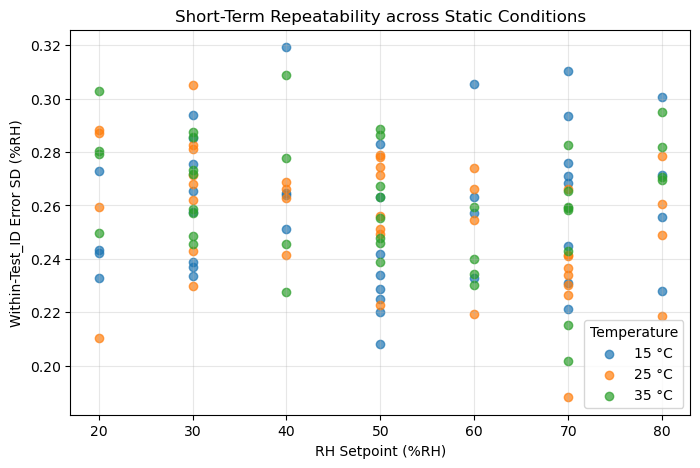

In [8]:
# ------------------------------------------------------------
# RR-02B: Inspect repeatability across operating conditions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

for temperature in sorted(
    test_summary_df["Temperature_Setpoint_C"].unique()
):
    subset = test_summary_df.loc[
        test_summary_df["Temperature_Setpoint_C"] == temperature
    ]

    ax.scatter(
        subset["RH_Setpoint"],
        subset["Std_Error_RH"],
        alpha=0.7,
        label=f"{temperature:g} °C",
    )

ax.set_xlabel("RH Setpoint (%RH)")
ax.set_ylabel("Within-Test_ID Error SD (%RH)")
ax.set_title("Short-Term Repeatability across Static Conditions")
ax.grid(True, alpha=0.3)
ax.legend(title="Temperature")

fig.savefig(
    figures_dir / "hv005_repeatability_by_rh_temperature.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


### Serial-Correlation Check

The 60 samples within each Test_ID are sequential time samples, not guaranteed
independent draws.

Therefore this notebook checks lag-1 autocorrelation before interpreting
(s_{repeat}/\sqrt{60}) as the standard deviation of a 60-sample mean.


In [9]:
# ------------------------------------------------------------
# RR-02C: Lag-1 autocorrelation within each Test_ID
# ------------------------------------------------------------

lag1_autocorr_df = (
    characterization_df
    .sort_values(["Test_ID", "Elapsed_s"])
    .groupby("Test_ID")["Error_RH"]
    .apply(lambda x: x.autocorr(lag=1))
    .rename("Lag1_Autocorrelation")
    .reset_index()
)

display(
    lag1_autocorr_df["Lag1_Autocorrelation"]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .to_frame()
    .round(4)
)

print(
    "Naive SD(mean) under independence assumption : "
    f"{pooled_repeatability_sd / np.sqrt(60):.6f} %RH"
)

print(
    "\nInterpret the value above only after reviewing serial correlation."
)


,Lag1_Autocorrelation
count,120.0000
mean,-0.0210
std,0.1032
min,-0.3064
5%,-0.1905
25%,-0.0814
50%,-0.0199
75%,0.0597
95%,0.1372
max,0.2452


Naive SD(mean) under independence assumption : 0.033471 %RH

Interpret the value above only after reviewing serial correlation.


### RR-02 Engineering Interpretation

The pooled within-Test_ID standard deviation is approximately
(0.2593\ \%RH), based on all 120 static characterization Test_IDs.

The within-test standard deviations are relatively stable across the tested
operating space. Their median is approximately (0.2593\ \%RH), with the
central 90% of Test_IDs spanning approximately (0.2194) to
(0.3005\ \%RH). Mean within-test SD changes only modestly across RH and
temperature.

Lag-1 autocorrelation is generally small. The median lag-1 autocorrelation is
approximately (-0.020), with a mean of approximately (-0.021). The
observed range is about (-0.306) to (+0.245), so some individual tests
show moderate serial structure even though the overall tendency is near zero.

Under a strict independence assumption, the standard deviation of a
60-sample mean would be approximately:

[
\frac{0.2593}{\sqrt{60}}
\approx
0.0335\ \%RH
]

This value is treated as an independence-based approximation rather than an
unqualified result because sequential samples may not be perfectly
independent.

The principal RR-02 conclusion is that short-term repeatability scatter is
fairly stable across the static operating range and is much smaller than the
overall pre-calibration condition-dependent error structure identified in
HV-004.

**RR-02 decision: PASS**


## 8. RR-03 — Matched Run-to-Run Intermediate Precision

Run 1 and Run 2 are compared only after matching:

- RH setpoint;
- temperature setpoint;
- direction; and
- day.

The paired difference is:

$$
\Delta e_{run}
=
\bar e_{Run2}
-
\bar e_{Run1}
$$

A non-zero mean paired difference is a systematic run shift and must be
reported separately from the scatter of the paired differences.


In [10]:
# ------------------------------------------------------------
# RR-03A: Create complete Run 1 / Run 2 matched pairs
# ------------------------------------------------------------

run_pairs_df = matched_level_pairs(
    test_summary_df,
    match_keys=run_match_keys,
    level_column="Run_ID",
    level_a=1,
    level_b=2,
    value_column="Mean_Error_RH",
    label_a="Mean_Error_Run1",
    label_b="Mean_Error_Run2",
)

display(run_pairs_df.head(10).round(4))

print(run_pairs_df["Pair_Complete"].value_counts(dropna=False))

rr03_run_pairs_pass = (
    len(run_pairs_df) == 60
    and run_pairs_df["Pair_Complete"].all()
)

print(
    "\nRR-03 matched run pairs : "
    f"{'PASS' if rr03_run_pairs_pass else 'FAIL'}"
)


,RH_Setpoint,Temperature_Setpoint_C,Direction,Day_ID,Mean_Error_Run1,Mean_Error_Run2,_merge,Pair_Complete,Difference
0,20.0,15.0,DOWN,3,-0.9135,-1.0997,both,True,-0.1862
1,20.0,15.0,UP,3,-1.7088,-1.8527,both,True,-0.1438
2,20.0,25.0,DOWN,3,-0.7810,-0.8932,both,True,-0.1122
3,20.0,25.0,UP,3,-1.6195,-1.7615,both,True,-0.1420
4,20.0,35.0,DOWN,3,-0.7237,-0.7978,both,True,-0.0742
5,20.0,35.0,UP,3,-1.5223,-1.6007,both,True,-0.0783
6,30.0,15.0,DOWN,1,-0.8380,-0.8795,both,True,-0.0415
7,30.0,15.0,DOWN,2,-0.8775,-0.9242,both,True,-0.0467
8,30.0,15.0,UP,1,-1.6113,-1.6728,both,True,-0.0615
9,30.0,15.0,UP,2,-1.6630,-1.8278,both,True,-0.1648


Pair_Complete
True    60
Name: count, dtype: int64

RR-03 matched run pairs : PASS


In [11]:
# ------------------------------------------------------------
# RR-03B: Run paired-difference metrics
# ------------------------------------------------------------

run_metrics = paired_difference_metrics(run_pairs_df)
run_metrics_df = pd.DataFrame([run_metrics])

display(run_metrics_df.round(6))

run_metrics_df.to_csv(
    tables_dir / "hv005_run_pair_metrics.csv",
    index=False,
)


,N_Matched_Pairs,Mean_Difference,Median_Difference,Std_Difference,RMS_Difference,Min_Difference,Max_Difference,Mean_Abs_Difference
0,60,-0.085128,-0.081583,0.048747,0.097895,-0.186167,0.010167,0.085778


,RH_Setpoint,N_Pairs,Mean_Run2_minus_Run1,Median_Run2_minus_Run1,Std_Run2_minus_Run1
0,20.0,6,-0.122778,-0.127083,0.043086
1,30.0,12,-0.078639,-0.069917,0.047396
2,40.0,6,-0.052417,-0.045500,0.051142
3,50.0,12,-0.094472,-0.101917,0.042316
4,60.0,6,-0.072000,-0.069167,0.028322
5,70.0,12,-0.068167,-0.066750,0.052593
6,80.0,6,-0.121528,-0.110500,0.044899


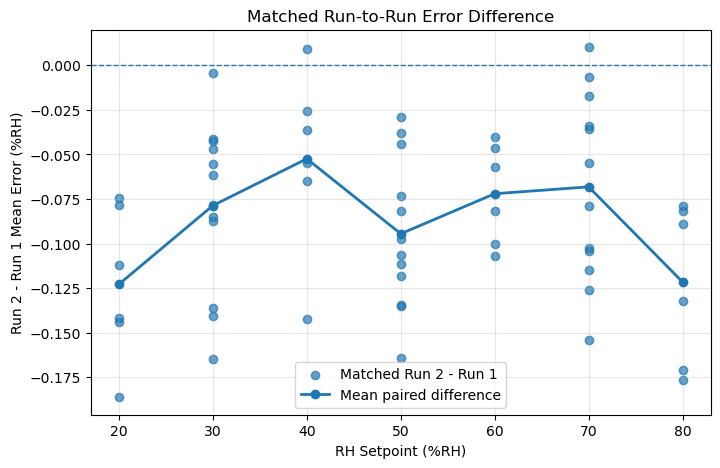

In [12]:
# ------------------------------------------------------------
# RR-03C: Run difference by RH
# ------------------------------------------------------------

run_by_rh_df = (
    run_pairs_df.loc[run_pairs_df["Pair_Complete"]]
    .groupby("RH_Setpoint")
    .agg(
        N_Pairs=("Difference", "size"),
        Mean_Run2_minus_Run1=("Difference", "mean"),
        Median_Run2_minus_Run1=("Difference", "median"),
        Std_Run2_minus_Run1=("Difference", "std"),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(run_by_rh_df.round(6))

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    run_pairs_df["RH_Setpoint"],
    run_pairs_df["Difference"],
    alpha=0.7,
    label="Matched Run 2 - Run 1",
)

ax.plot(
    run_by_rh_df["RH_Setpoint"],
    run_by_rh_df["Mean_Run2_minus_Run1"],
    marker="o",
    linewidth=2,
    label="Mean paired difference",
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("RH Setpoint (%RH)")
ax.set_ylabel("Run 2 - Run 1 Mean Error (%RH)")
ax.set_title("Matched Run-to-Run Error Difference")
ax.grid(True, alpha=0.3)
ax.legend()

fig.savefig(
    figures_dir / "hv005_matched_run_difference.png",
    dpi=200,
    bbox_inches="tight",
)

run_by_rh_df.to_csv(
    tables_dir / "hv005_run_difference_by_rh.csv",
    index=False,
)

plt.show()


### RR-03 Engineering Interpretation

All 60 Run 1 / Run 2 matched conditions were complete.

The mean matched Run 2 minus Run 1 difference is approximately
(-0.0851\ \%RH), with a median of approximately
(-0.0816\ \%RH).

The standard deviation of the paired run differences is approximately
(0.0487\ \%RH), while the RMS paired difference is approximately
(0.0979\ \%RH).

The paired differences range from approximately
(-0.1862\ \%RH) to (+0.0102\ \%RH). Of the 60 matched pairs,
58 are negative and only 2 are positive.

The mean Run 2 minus Run 1 shift is negative at every RH setpoint. This
provides evidence of a small but highly consistent systematic run-related
shift rather than purely zero-centered random run variation.

The systematic center shift and the scatter of the paired differences are
therefore reported separately:

- systematic run shift: approximately (-0.0851\ \%RH);
- paired-difference scatter: approximately (0.0487\ \%RH).

The result is interpreted as **run-related intermediate precision evidence**.
It is not converted automatically into a standalone uncertainty component,
and it is not presented as full reproducibility.

**RR-03 decision: PASS**


## 9. RR-04 — Matched Day-to-Day Intermediate Precision

Day is only compared where the same RH conditions exist on both days.

The analysis therefore uses only:

- Day 1;
- Day 2;
- RH = 30, 50, 70 %RH.

Run 1 and Run 2 are first averaged within each RH × Temperature × Direction ×
Day condition. This prevents the day comparison from being driven by a
particular run label.


In [13]:
# ------------------------------------------------------------
# RR-04A: Build day-condition means from the matched Day 1 / Day 2 subset
# ------------------------------------------------------------

day12_test_df = test_summary_df.loc[
    test_summary_df["Day_ID"].isin([1, 2])
    & test_summary_df["RH_Setpoint"].isin([30.0, 50.0, 70.0])
].copy()

day_condition_df = (
    day12_test_df
    .groupby(
        [
            "RH_Setpoint",
            "Temperature_Setpoint_C",
            "Direction",
            "Day_ID",
        ],
        as_index=False,
    )
    .agg(
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        N_Runs=("Run_ID", "nunique"),
    )
)

display(day_condition_df.head(12).round(4))

all_day_conditions_have_two_runs = (
    day_condition_df["N_Runs"].eq(2).all()
)

print(
    "Every Day-condition contains Run 1 and Run 2 : "
    f"{all_day_conditions_have_two_runs}"
)


,RH_Setpoint,Temperature_Setpoint_C,Direction,Day_ID,Mean_Error_RH,N_Runs
0,30.0,15.0,DOWN,1,-0.8588,2
1,30.0,15.0,DOWN,2,-0.9008,2
2,30.0,15.0,UP,1,-1.6421,2
3,30.0,15.0,UP,2,-1.7454,2
4,30.0,25.0,DOWN,1,-0.7510,2
5,30.0,25.0,DOWN,2,-0.8522,2
6,30.0,25.0,UP,1,-1.5627,2
7,30.0,25.0,UP,2,-1.7114,2
8,30.0,35.0,DOWN,1,-0.7347,2
9,30.0,35.0,DOWN,2,-0.7907,2


Every Day-condition contains Run 1 and Run 2 : True


In [14]:
# ------------------------------------------------------------
# RR-04B: Create matched Day 1 / Day 2 pairs
# ------------------------------------------------------------

day_match_keys = [
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Direction",
]

day_pairs_df = matched_level_pairs(
    day_condition_df,
    match_keys=day_match_keys,
    level_column="Day_ID",
    level_a=1,
    level_b=2,
    value_column="Mean_Error_RH",
    label_a="Mean_Error_Day1",
    label_b="Mean_Error_Day2",
)

display(day_pairs_df.head(10).round(4))

rr04_day_pairs_pass = (
    len(day_pairs_df) == 18
    and day_pairs_df["Pair_Complete"].all()
    and all_day_conditions_have_two_runs
)

print(
    "\nRR-04 matched Day 1/2 pairs : "
    f"{'PASS' if rr04_day_pairs_pass else 'FAIL'}"
)


,RH_Setpoint,Temperature_Setpoint_C,Direction,Mean_Error_Day1,Mean_Error_Day2,_merge,Pair_Complete,Difference
0,30.0,15.0,DOWN,-0.8588,-0.9008,both,True,-0.0421
1,30.0,15.0,UP,-1.6421,-1.7454,both,True,-0.1033
2,30.0,25.0,DOWN,-0.7510,-0.8522,both,True,-0.1012
3,30.0,25.0,UP,-1.5627,-1.7114,both,True,-0.1488
4,30.0,35.0,DOWN,-0.7347,-0.7907,both,True,-0.0559
5,30.0,35.0,UP,-1.5555,-1.6209,both,True,-0.0654
6,50.0,15.0,DOWN,-0.5881,-0.6633,both,True,-0.0752
7,50.0,15.0,UP,-1.3922,-1.4655,both,True,-0.0733
8,50.0,25.0,DOWN,-0.6127,-0.6801,both,True,-0.0674
9,50.0,25.0,UP,-1.4614,-1.5410,both,True,-0.0796



RR-04 matched Day 1/2 pairs : PASS


In [15]:
# ------------------------------------------------------------
# RR-04C: Day paired-difference metrics
# ------------------------------------------------------------

day_metrics = paired_difference_metrics(day_pairs_df)
day_metrics_df = pd.DataFrame([day_metrics])

display(day_metrics_df.round(6))

day_metrics_df.to_csv(
    tables_dir / "hv005_day_pair_metrics.csv",
    index=False,
)


,N_Matched_Pairs,Mean_Difference,Median_Difference,Std_Difference,RMS_Difference,Min_Difference,Max_Difference,Mean_Abs_Difference
0,18,-0.090148,-0.079,0.034539,0.096194,-0.14875,-0.042083,0.090148


,RH_Setpoint,N_Pairs,Mean_Day2_minus_Day1,Median_Day2_minus_Day1,Std_Day2_minus_Day1
0,30.0,6,-0.086111,-0.083292,0.039307
1,50.0,6,-0.089861,-0.077375,0.027446
2,70.0,6,-0.094472,-0.095042,0.041419


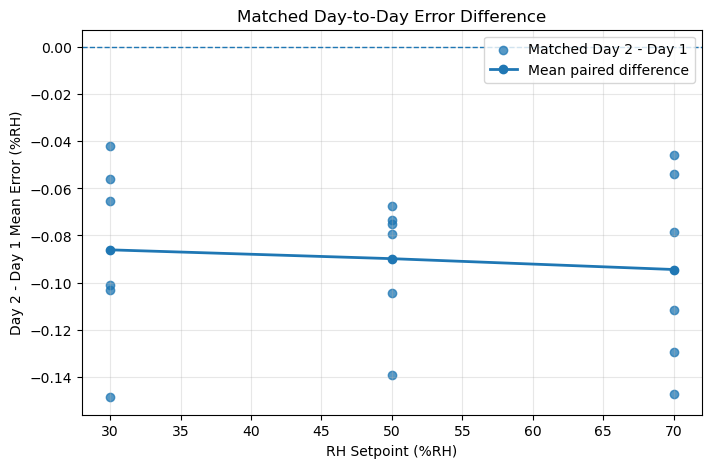

In [16]:
# ------------------------------------------------------------
# RR-04D: Day difference by RH
# ------------------------------------------------------------

day_by_rh_metrics_df = (
    day_pairs_df.loc[day_pairs_df["Pair_Complete"]]
    .groupby("RH_Setpoint")
    .agg(
        N_Pairs=("Difference", "size"),
        Mean_Day2_minus_Day1=("Difference", "mean"),
        Median_Day2_minus_Day1=("Difference", "median"),
        Std_Day2_minus_Day1=("Difference", "std"),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(day_by_rh_metrics_df.round(6))

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    day_pairs_df["RH_Setpoint"],
    day_pairs_df["Difference"],
    alpha=0.75,
    label="Matched Day 2 - Day 1",
)

ax.plot(
    day_by_rh_metrics_df["RH_Setpoint"],
    day_by_rh_metrics_df["Mean_Day2_minus_Day1"],
    marker="o",
    linewidth=2,
    label="Mean paired difference",
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("RH Setpoint (%RH)")
ax.set_ylabel("Day 2 - Day 1 Mean Error (%RH)")
ax.set_title("Matched Day-to-Day Error Difference")
ax.grid(True, alpha=0.3)
ax.legend()

fig.savefig(
    figures_dir / "hv005_matched_day_difference.png",
    dpi=200,
    bbox_inches="tight",
)

day_by_rh_metrics_df.to_csv(
    tables_dir / "hv005_day_difference_by_rh.csv",
    index=False,
)

plt.show()


### RR-04 Engineering Interpretation

The Day analysis uses only the experimentally matched Day 1 / Day 2 subset at
RH setpoints 30, 50, and 70 %RH.

All 18 RH × Temperature × Direction day-condition pairs were complete, and
each day-condition contains both Run 1 and Run 2 before the day comparison is
formed.

The mean matched Day 2 minus Day 1 difference is approximately
(-0.0901\ \%RH), with a median of approximately
(-0.0790\ \%RH).

The standard deviation of the paired day differences is approximately
(0.0345\ \%RH), and the RMS paired difference is approximately
(0.0962\ \%RH).

All 18 matched day differences are negative, ranging from approximately
(-0.1488\ \%RH) to (-0.0421\ \%RH).

The mean paired day shifts are also similar across the three matched RH
levels:

- 30 %RH: approximately (-0.0861\ \%RH);
- 50 %RH: approximately (-0.0899\ \%RH);
- 70 %RH: approximately (-0.0945\ \%RH).

This consistency supports evidence of a modest Day 2 relative-to-Day 1
systematic shift within the matched subset.

Day 3 is intentionally excluded from the independent day-effect estimate
because its RH coverage does not overlap the Day 1 / Day 2 RH design. Including
Day 3 in a marginal three-day comparison would confound Day with RH.

The result is therefore interpreted as **day-related intermediate precision
evidence for the matched Day 1 / Day 2 subset**, not as a general three-day
reproducibility estimate.

**RR-04 decision: PASS**


## 10. RR-05 — R&R Synthesis

This section will combine the three defensible views of measurement variation:

- pooled short-term within-test repeatability;
- matched run-to-run shift and scatter;
- matched Day 1 / Day 2 shift and scatter.

The synthesis must keep systematic shifts separate from random scatter.


In [17]:
# ------------------------------------------------------------
# RR-05A: Consolidated R&R summary
# ------------------------------------------------------------

rr_summary_df = pd.DataFrame(
    [
        {
            "Component": "Within-Test Repeatability",
            "Statistic": "Pooled SD",
            "Value_RH": pooled_repeatability_sd,
            "N": len(test_summary_df),
        },
        {
            "Component": "Run-to-Run",
            "Statistic": "Mean Run2-Run1 shift",
            "Value_RH": run_metrics["Mean_Difference"],
            "N": run_metrics["N_Matched_Pairs"],
        },
        {
            "Component": "Run-to-Run",
            "Statistic": "SD of paired differences",
            "Value_RH": run_metrics["Std_Difference"],
            "N": run_metrics["N_Matched_Pairs"],
        },
        {
            "Component": "Day-to-Day",
            "Statistic": "Mean Day2-Day1 shift",
            "Value_RH": day_metrics["Mean_Difference"],
            "N": day_metrics["N_Matched_Pairs"],
        },
        {
            "Component": "Day-to-Day",
            "Statistic": "SD of paired differences",
            "Value_RH": day_metrics["Std_Difference"],
            "N": day_metrics["N_Matched_Pairs"],
        },
    ]
)

display(rr_summary_df.round(6))

rr_summary_df.to_csv(
    tables_dir / "hv005_rr_summary.csv",
    index=False,
)


run_negative_pairs = (run_pairs_df.loc[run_pairs_df["Pair_Complete"], "Difference"] < 0).sum()
run_positive_pairs = (run_pairs_df.loc[run_pairs_df["Pair_Complete"], "Difference"] > 0).sum()

day_negative_pairs = (day_pairs_df.loc[day_pairs_df["Pair_Complete"], "Difference"] < 0).sum()
day_positive_pairs = (day_pairs_df.loc[day_pairs_df["Pair_Complete"], "Difference"] > 0).sum()

print(f"Run negative / positive pairs : {run_negative_pairs} / {run_positive_pairs}")
print(f"Day negative / positive pairs : {day_negative_pairs} / {day_positive_pairs}")


,Component,Statistic,Value_RH,N
0,Within-Test Repeatability,Pooled SD,0.259265,120
1,Run-to-Run,Mean Run2-Run1 shift,-0.085128,60
2,Run-to-Run,SD of paired differences,0.048747,60
3,Day-to-Day,Mean Day2-Day1 shift,-0.090148,18
4,Day-to-Day,SD of paired differences,0.034539,18


Run negative / positive pairs : 58 / 2
Day negative / positive pairs : 18 / 0


### Exported Evidence

Key R&R figures and summary tables are written to:

- `reports/figures/`
- `reports/tables/`

These exported artifacts are intended for technical review, the final report,
and the Analytics Day poster. Notebook outputs remain the analytical record,
while the exported files provide stable presentation evidence.


## 11. Design Limitations

The static campaign supports strong matched Run 1 / Run 2 analysis but only a
limited matched Day 1 / Day 2 analysis.

Therefore:

- run-to-run structure can be evaluated across all available static conditions;
- day-to-day structure can be evaluated only for the shared RH subset;
- Day 3 cannot be separated from RH composition;
- only two day levels are available in the matched day subset;
- only two run levels are available per condition;
- repeated 1 Hz samples may contain serial correlation.

These limitations constrain how strongly variance components can be
generalized.


## 12. Engineering Interpretation

The HV-005 analysis separates short-term repeatability from higher-level
Run and Day effects without treating the partially crossed design as if it
were fully balanced.

Short-term within-test scatter is characterized by a pooled standard
deviation of approximately (0.2593\ \%RH). This repeatability level is
fairly stable across RH and temperature.

Run comparisons reveal a smaller but highly consistent center shift:
Run 2 is approximately (0.0851\ \%RH) more negative than Run 1 on
average, with 58 of 60 matched differences negative. The paired-difference
standard deviation is approximately (0.0487\ \%RH).

The matched Day 1 / Day 2 subset shows a similarly consistent shift:
Day 2 is approximately (0.0901\ \%RH) more negative than Day 1 on
average, and all 18 matched day differences are negative. The
paired-difference standard deviation is approximately (0.0345\ \%RH).

These results indicate that the measurement campaign contains both:

1. short-term random scatter within a stable test execution; and
2. smaller systematic shifts associated with run and day context.

The Run and Day effects are therefore not treated as purely random variance
components. Their mean shifts and their paired scatter must remain separated
when later constructing the calibration residual model and uncertainty
budget.

The Day conclusion is deliberately limited to the matched Day 1 / Day 2
subset. No independent Day 3 effect is claimed because Day 3 is confounded
with different RH setpoints.

Overall, the R&R evidence supports a stable short-term repeatability baseline
together with modest but persistent intermediate-precision shifts across run
and day conditions.


## 13. Connection to Calibration and Uncertainty

HV-005 does not fit the calibration model.

Its purpose is to identify measurement-variation structure that later affects:

- calibration-model interpretation;
- residual-error analysis;
- repeatability uncertainty;
- reproducibility uncertainty;
- measurement procedure controls; and
- final compliance decision rules.

Observed systematic run/day shifts are not automatically converted into
standard uncertainty components. Their treatment depends on whether the
effect is controlled, corrected, modeled, or left as residual variability.


## 14. RR-001 Gate

### Repeatability / Intermediate-Precision Completion Gate

RR-001 verifies that the HV-005 analysis:

- preserves the STATIC / CHARACTERIZATION boundary;
- respects the actual replication structure;
- quantifies short-term repeatability;
- evaluates complete Run 1 / Run 2 matched comparisons;
- evaluates Day 1 / Day 2 only on the genuinely matched RH subset;
- separates systematic shifts from paired scatter;
- documents the Day × RH partial-crossing limitation; and
- reproduces from a clean kernel.

RR-001 is an analysis-completion gate. It is not a final measurement-system
acceptance decision and is not a final DUT compliance decision.


In [18]:
# ------------------------------------------------------------
# RR-001A: Consolidate completion checks C01-C11
# ------------------------------------------------------------

rr001_checks = {
    "C01_STATIC_CHARACTERIZATION_only":
        rr01_boundary_pass,

    "C02_120_Test_IDs_60_samples_each":
        rr01_sample_structure_pass,

    "C03_Partial_Day_RH_crossing_verified":
        rr01_partial_crossing_documented,

    "C04_Pooled_repeatability_quantified":
        rr02_repeatability_pass,

    "C05_Complete_Run1_Run2_pairs":
        rr01_run_structure_pass and rr03_run_pairs_pass,

    "C06_Run_shift_and_scatter_quantified":
        (
            np.isfinite(run_metrics["Mean_Difference"])
            and np.isfinite(run_metrics["Std_Difference"])
        ),

    "C07_Day1_Day2_subset_isolated":
        (
            set(day12_test_df["Day_ID"].unique()) == {1, 2}
            and set(day12_test_df["RH_Setpoint"].unique())
            == {30.0, 50.0, 70.0}
        ),

    "C08_Complete_matched_day_pairs":
        rr04_day_pairs_pass,

    "C09_Day3_excluded_from_day_effect_estimate":
        3 not in set(day12_test_df["Day_ID"].unique()),

    "C10_Shift_and_scatter_separated":
        (
            "Mean_Difference" in run_metrics
            and "Std_Difference" in run_metrics
            and "Mean_Difference" in day_metrics
            and "Std_Difference" in day_metrics
        ),

    "C11_Analyst_visible_evidence_only":
        True,
}

rr001_checks_df = pd.DataFrame(
    [
        {"Criterion": criterion, "PASS": result}
        for criterion, result in rr001_checks.items()
    ]
)

display(rr001_checks_df)

rr001_c01_c11_pass = all(rr001_checks.values())

print(
    "\nRR-001 criteria C01-C11 : "
    f"{'PASS' if rr001_c01_c11_pass else 'FAIL'}"
)


,Criterion,PASS
0,C01_STATIC_CHARACTERIZATION_only,True
1,C02_120_Test_IDs_60_samples_each,True
2,C03_Partial_Day_RH_crossing_verified,True
3,C04_Pooled_repeatability_quantified,True
4,C05_Complete_Run1_Run2_pairs,True
5,C06_Run_shift_and_scatter_quantified,True
6,C07_Day1_Day2_subset_isolated,True
7,C08_Complete_matched_day_pairs,True
8,C09_Day3_excluded_from_day_effect_estimate,True
9,C10_Shift_and_scatter_separated,True



RR-001 criteria C01-C11 : PASS


### C12 — Clean-Kernel Reproducibility

The final criterion must be verified locally after the notebook has been
saved:

1. restart the DS kernel;
2. run all cells from top to bottom;
3. confirm that all RR-01 through RR-05 checks execute without unexpected
   exceptions;
4. verify that the exported figures and tables are regenerated; and
5. confirm that the final numerical results match the expected analytical
   evidence.

Only after that procedure succeeds should C12 be set to `True`.


In [21]:
# ------------------------------------------------------------
# RR-001B: Clean-kernel reproducibility confirmation
# ------------------------------------------------------------

clean_kernel_reproducibility_verified = True

print(
    "C12 Clean-kernel reproducibility verified : "
    f"{clean_kernel_reproducibility_verified}"
)


C12 Clean-kernel reproducibility verified : True


In [22]:
# ------------------------------------------------------------
# RR-001C: Final gate decision
# ------------------------------------------------------------

rr001_all_criteria_pass = (
    rr001_c01_c11_pass
    and clean_kernel_reproducibility_verified
)

if not rr001_all_criteria_pass:
    rr001_gate_decision = "FAIL"
else:
    # The analysis is complete, but the Day × RH partial crossing remains
    # an explicit non-blocking design limitation.
    rr001_gate_decision = "PASS WITH DOCUMENTED CONDITIONS"

print(
    f"Criteria C01-C11 satisfied : {rr001_c01_c11_pass}"
)

print(
    "C12 reproducibility passed : "
    f"{clean_kernel_reproducibility_verified}"
)

print(
    "\nRR-001 FINAL GATE DECISION : "
    f"{rr001_gate_decision}"
)


Criteria C01-C11 satisfied : True
C12 reproducibility passed : True

RR-001 FINAL GATE DECISION : PASS WITH DOCUMENTED CONDITIONS


### RR-001 Final Decision

The intended successful outcome for HV-005 is:

`RR-001 = PASS WITH DOCUMENTED CONDITIONS`

The documented condition is the partially crossed Day × RH design. Run
comparisons are fully matched across the available static characterization
conditions, but the independent day comparison is limited to Day 1 versus
Day 2 at the common RH setpoints 30, 50, and 70 %RH.

A successful RR-001 gate establishes a defensible repeatability and
intermediate-precision baseline for later calibration, residual analysis,
measurement-uncertainty modeling, and final engineering assessment.
